## 1. Import Libraries

In [27]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

pd.set_option('display.max_colwidth', 120)

## 2. Load Dataset

In [28]:
# Make sure nlp_dataset.csv is in the same folder as this notebook
df = pd.read_csv("nlp_dataset.csv")

df.head()

,Comment,Emotion
0,i seriously hate one subject to death but now i feel reluctant to drop it,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...,fear
3,ive been really angry with r and i feel like an idiot for trusting him in the first place,joy
4,i feel suspicious if there is no one outside like the rapture has happened or something,fear


## 3. Understand the Dataset

In [29]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.info()

Shape: (5937, 2)

Columns:
['Comment', 'Emotion']
<class 'pandas.DataFrame'>
RangeIndex: 5937 entries, 0 to 5936
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Comment  5937 non-null   str  
 1   Emotion  5937 non-null   str  
dtypes: str(2)
memory usage: 92.9 KB


In [30]:
df.isnull().sum()

Comment    0
Emotion    0
dtype: int64

In [31]:
df.duplicated().sum()

np.int64(0)

In [32]:
df.describe(include='all')

,Comment,Emotion
count,5937,5937
unique,5934,3
top,i resorted to yesterday the post peak day of illness when i was still housebound but feeling agitated and peckish fo...,anger
freq,2,2000


### Emotion distribution

In [33]:
df['Emotion'].value_counts()

Emotion
anger    2000
joy      2000
fear     1937
Name: count, dtype: int64

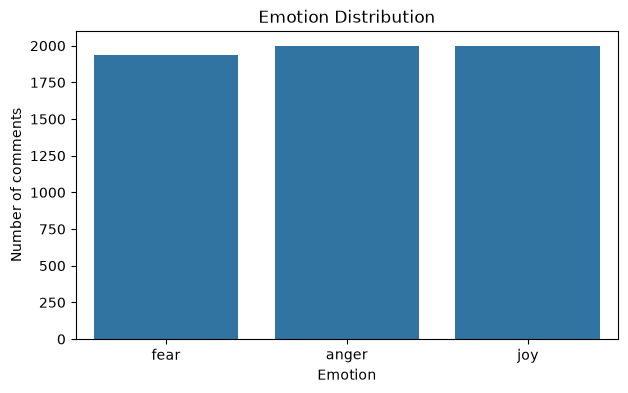

In [34]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Emotion')
plt.title("Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of comments")
plt.show()

## 4. Handle Missing Values and Duplicates

The supplied dataset has no missing values and no duplicate rows. The following cell is included to make the notebook robust if the CSV changes.

In [35]:
df = df.dropna(subset=['Comment', 'Emotion']).drop_duplicates().copy()
df['Comment'] = df['Comment'].astype(str)
df['Emotion'] = df['Emotion'].astype(str)

print("Shape after basic cleaning:", df.shape)

Shape after basic cleaning: (5937, 2)


## 5. Text Cleaning

In [50]:
def clean_text(text):
    text = text.lower()                         # convert to lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)    # remove punctuation, numbers and symbols
    text = re.sub(r'\s+', ' ', text)          # remove extra spaces
    return text.strip()

df['Cleaned_Comment'] = df['Comment'].apply(clean_text)
df[['Comment', 'Cleaned_Comment']].head()

,Comment,Cleaned_Comment
0,i seriously hate one subject to death but now i feel reluctant to drop it,i seriously hate one subject to death but now i feel reluctant to drop it
1,im so full of life i feel appalled,im so full of life i feel appalled
2,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...
3,ive been really angry with r and i feel like an idiot for trusting him in the first place,ive been really angry with r and i feel like an idiot for trusting him in the first place
4,i feel suspicious if there is no one outside like the rapture has happened or something,i feel suspicious if there is no one outside like the rapture has happened or something


## 6. Tokenization

In [37]:
# Split each cleaned sentence into individual words (tokens)
df['Tokens'] = df['Cleaned_Comment'].apply(lambda text: text.split())
df[['Cleaned_Comment', 'Tokens']].head()

,Cleaned_Comment,Tokens
0,i seriously hate one subject to death but now i feel reluctant to drop it,"[i, seriously, hate, one, subject, to, death, but, now, i, feel, reluctant, to, drop, it]"
1,im so full of life i feel appalled,"[im, so, full, of, life, i, feel, appalled]"
2,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...,"[i, sit, here, to, write, i, start, to, dig, out, my, feelings, and, i, think, that, i, am, afraid, to, accept, the,..."
3,ive been really angry with r and i feel like an idiot for trusting him in the first place,"[ive, been, really, angry, with, r, and, i, feel, like, an, idiot, for, trusting, him, in, the, first, place]"
4,i feel suspicious if there is no one outside like the rapture has happened or something,"[i, feel, suspicious, if, there, is, no, one, outside, like, the, rapture, has, happened, or, something]"


## 7. Stopword Removal

In [38]:
# Use scikit-learn's built-in English stopword list (no NLTK download required)
stop_words = set(ENGLISH_STOP_WORDS)

df['Processed_Comment'] = df['Tokens'].apply(
    lambda tokens: ' '.join([word for word in tokens if word not in stop_words])
)

df[['Cleaned_Comment', 'Processed_Comment']].head()

,Cleaned_Comment,Processed_Comment
0,i seriously hate one subject to death but now i feel reluctant to drop it,seriously hate subject death feel reluctant drop
1,im so full of life i feel appalled,im life feel appalled
2,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...,sit write start dig feelings think afraid accept possibility make
3,ive been really angry with r and i feel like an idiot for trusting him in the first place,ive really angry r feel like idiot trusting place
4,i feel suspicious if there is no one outside like the rapture has happened or something,feel suspicious outside like rapture happened


### Preprocessing explanation

- **Text cleaning:** converts text to lowercase and removes punctuation, numbers and unnecessary symbols.
- **Tokenization:** splits each sentence into individual words.
- **Stopword removal:** removes common English words using the built-in English stopword list.
- These steps reduce text noise and prepare the comments for numerical feature extraction.

## 8. Separate Input and Target

In [39]:
X = df['Processed_Comment']
y = df['Emotion']

print("Input samples:", X.shape[0])
print("\nTarget categories:")
print(y.value_counts())

Input samples: 5937

Target categories:
Emotion
anger    2000
joy      2000
fear     1937
Name: count, dtype: int64


## 9. Train-Test Split

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4749
Testing samples: 1188


## 10. Feature Extraction using TF-IDF

In [41]:
tfidf = TfidfVectorizer(max_features=5000)

# Fit only on training text; transform test text using the learned vocabulary
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (4749, 5000)
Testing feature shape: (1188, 5000)


**TF-IDF explanation:** TfidfVectorizer converts text into numerical feature vectors. It gives higher importance to words that are useful in a document but less common across the full collection of documents.

## 11. Model 1 – Naive Bayes

In [42]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print("Naive Bayes Weighted F1-score:", f1_score(y_test, nb_pred, average='weighted'))

Naive Bayes Accuracy: 0.9040404040404041
Naive Bayes Weighted F1-score: 0.9041229159858839


## 12. Model 2 – Support Vector Machine (SVM)

In [43]:
svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print("SVM Weighted F1-score:", f1_score(y_test, svm_pred, average='weighted'))

SVM Accuracy: 0.9436026936026936
SVM Weighted F1-score: 0.943575873644522


## 13. Classification Reports

In [44]:
print("NAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(y_test, nb_pred))

NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

       anger       0.90      0.91      0.90       400
        fear       0.88      0.92      0.90       388
         joy       0.94      0.88      0.91       400

    accuracy                           0.90      1188
   macro avg       0.90      0.90      0.90      1188
weighted avg       0.91      0.90      0.90      1188



In [45]:
print("SVM CLASSIFICATION REPORT")
print(classification_report(y_test, svm_pred))

SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

       anger       0.95      0.93      0.94       400
        fear       0.94      0.95      0.94       388
         joy       0.94      0.96      0.95       400

    accuracy                           0.94      1188
   macro avg       0.94      0.94      0.94      1188
weighted avg       0.94      0.94      0.94      1188



## 14. Model Comparison

In [46]:
results = pd.DataFrame({
    'Model': ['Naive Bayes', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, svm_pred)
    ],
    'Weighted F1-score': [
        f1_score(y_test, nb_pred, average='weighted'),
        f1_score(y_test, svm_pred, average='weighted')
    ]
})

results

,Model,Accuracy,Weighted F1-score
0,Naive Bayes,0.904040,0.904123
1,SVM,0.943603,0.943576


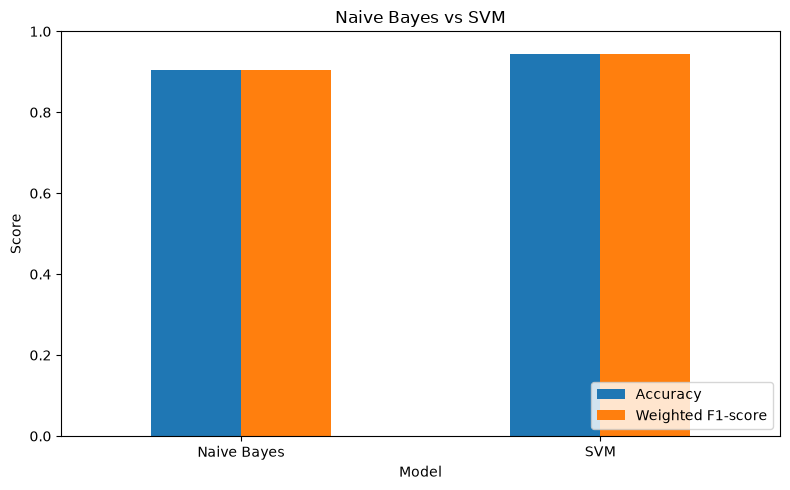

In [47]:
results.set_index('Model').plot(kind='bar', figsize=(8, 5), ylim=(0, 1))
plt.title("Naive Bayes vs SVM")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 15. Confusion Matrices

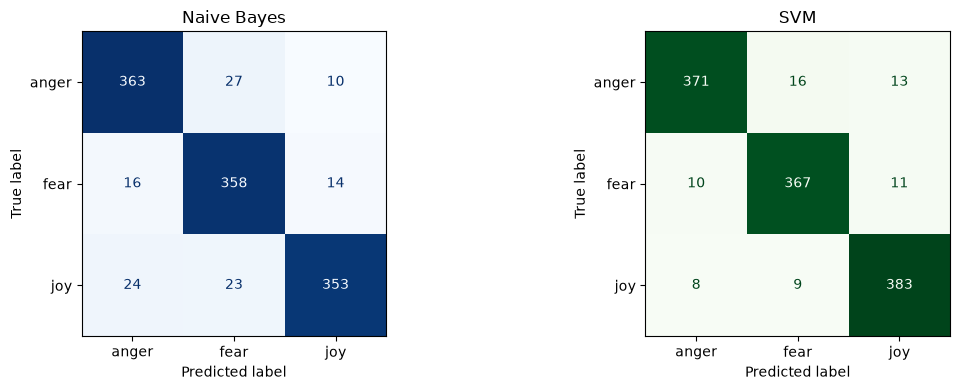

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, nb_pred, ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title("Naive Bayes")

ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred, ax=axes[1], cmap='Greens', colorbar=False
)
axes[1].set_title("SVM")

plt.tight_layout()
plt.show()

## 16. Model Comparison Explanation

Naive Bayes is a probabilistic machine learning algorithm based on Bayes' theorem. It is simple and computationally efficient for text classification.

Support Vector Machine (SVM) is a supervised machine learning algorithm that finds a decision boundary to separate classes. Linear SVM often works well with high-dimensional text features.

The models are compared using accuracy and weighted F1-score. The model with the stronger evaluation scores performs better on this test split. Use the results printed above to identify the better model; do not assume a winner before running the notebook.

## 17. Conclusion

The Sentiment Analysis project uses text comments to classify emotions into the categories available in the dataset. Text preprocessing includes cleaning, tokenization and stopword removal. TF-IDF is used to convert text into numerical features. Naive Bayes and Support Vector Machine models are trained and evaluated using accuracy and weighted F1-score. The comparison helps identify which of the two models performs better for this dataset.